# **KHỞI TẠO VÀ KẾT NỐI**

In [28]:
!pip install -q duckdb
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

FOLDER = '/content/drive/MyDrive/Colab Notebooks'
ORIG = f'{FOLDER}/origination_data-2.csv'
PERF = f'{FOLDER}/monthly_performance-2.csv'

# Thư mục lưu 4 file CSV sạch xuất ra cho Power BI
OUT_DIR = f'{FOLDER}/powerbi_exports'
os.makedirs(OUT_DIR, exist_ok=True)

con = duckdb.connect()

In [29]:
df_origination = pd.read_csv(ORIG)
df_origination.head()

,customer_id,application_date,age,gender,employment_status,annual_income,monthly_income,loan_amount,interest_rate,loan_term,emi,dti,credit_score_origination,revolving_utilization_origination,credit_inquiries_12m,deterioration_pattern,default_12m,vintage_year,vintage_month
0,CUST100000,2022-04-08,42,Male,Self-Employed,83834.0,6986.17,50000.0,12.33,36,1668.61,0.35,720,0.433,0,stable,0,2022,2022-04
1,CUST100001,2024-04-28,35,Female,Employed,56472.0,4706.00,50000.0,10.98,48,1291.79,0.41,658,0.250,1,gradual_decline,0,2024,2024-04
2,CUST100002,2023-12-19,44,Male,Employed,165696.0,13808.00,50000.0,9.71,84,822.59,0.44,801,0.339,2,stable,0,2023,2023-12
3,CUST100003,2023-04-27,41,Female,Employed,79943.0,6661.92,50000.0,14.42,36,1719.10,0.38,743,0.617,0,gradual_decline,0,2023,2023-04
4,CUST100004,2023-04-20,28,Female,Employed,160442.0,13370.17,52071.0,10.81,36,1700.06,0.10,662,0.215,1,stable,0,2023,2023-04


In [30]:
df_performance = pd.read_csv(PERF)
df_performance.head()

,customer_id,observation_month,months_on_book,dpd_current,payment_made,payment_amount,scheduled_emi,credit_score,credit_score_delta_3m,revolving_utilization,revolving_util_delta_3m,has_defaulted,will_default_original
0,CUST100000,2022-05,1,0,1,1668.61,1668.61,722,2,0.443,0.010,0,0
1,CUST100000,2022-06,2,0,1,1668.61,1668.61,720,0,0.435,0.002,0,0
2,CUST100000,2022-07,3,0,1,1668.61,1668.61,718,-2,0.417,-0.016,0,0
3,CUST100000,2022-08,4,0,1,1668.61,1668.61,720,6,0.421,0.013,0,0
4,CUST100000,2022-09,5,0,1,1668.61,1668.61,721,3,0.427,0.020,0,0


## **Data Dictionary**

**Origination Data**
*   **customer_id**: Unique customer identifier
*   **application_date**: Date when loan application was submitted
*   **age**: 	Customer age at application (years)
*   **gender**: Customer gender
*  **employment_status**: Employment status at origination
*   **annual_income**: Gross annual income (currency units)
*   **monthly_income**: Gross monthly income (annual/12)
*   **loan_amount**: Principal loan amount disbursed
*   **interest_rate**: Annual percentage rate (APR)
*   **loan_term**: Loan tenure in months
*   **emi**: Equated Monthly Installment (calculated using standard amortization formula)
*   **credit_score_origination**: Credit bureau score at application time (FICO-style)
*   **dti**: Debt-to-Income ratio (monthly debt obligations / monthly income)
*   **revolving_utilization_origination**: Credit card utilization rate at origination (used credit / available credit)
*   **credit_inquiries_12m**: 	Number of hard credit inquiries in past 12 months
*   **deterioration_pattern**: Simulated customer lifecycle behavior pattern
*   **default_12m**: TARGET VARIABLE - Whether customer defaults within 12 months (1=Yes, 0=No)
*   **vintage_year**: Year of loan origination (for cohort analysis)
*   **vintage_month**: Year-month of origination (for vintage tracking)












**Monthly Performance**
*   **customer_id**: Links to origination data
*   **observation_month**: The calendar month of this observation
*   **months_on_book**: Number of months since origination (account age)
*   **dpd_current**: 	Days Past Due in current month (0=current, 90+=default)
*   **payment_made**: 	Whether scheduled EMI payment was made this month
*   **payment_amount**: Actual payment amount received
*   **scheduled_emi**: Expected monthly payment amount
*   **credit_score**: Current credit bureau score (updated monthly)
*   **credit_score_delta_3m**: 	Change in credit score over past 3 months
*   **revolving_utilization**: Current credit card utilization rate
*   **revolving_util_delta_3m**: Change in utilization over past 3 months
*   **has_defaulted**: Whether customer has entered default status (90+ DPD) by this month
*   **will_default_original**: Ground truth from origination (duplicates default_12m for convenience)





# **KIỂM TRA VÀ LÀM SẠCH**

In [31]:
# Kiểm tra số lượng khoản vay và các mức DPD thực tế
print("1. Quy mô bảng Origination:")
display(con.execute(f"SELECT COUNT(*) AS loans, MIN(vintage_month) AS tu_thang, MAX(vintage_month) AS den_thang FROM '{ORIG}'").df())

print("\n2. Các mức quá hạn (DPD) trong bảng Performance:")
display(con.execute(f"SELECT dpd_current, has_defaulted, COUNT(*) AS rows FROM '{PERF}' GROUP BY 1, 2 ORDER BY 1").df())

1. Quy mô bảng Origination:


,loans,tu_thang,den_thang
0,135000,2022-01,2024-12



2. Các mức quá hạn (DPD) trong bảng Performance:


,dpd_current,has_defaulted,rows
0,0,0,2246724
1,90,1,109037


*   Dữ liệu không ghi nhận nấc 30/60 DPD nên mọi khoản vay chuyển trạng thái trực  tiếp từ Current (0) sang NPL (90+).
*  Vì không có nấc 30/60 DPD để cảnh báo sớm, ta sẽ dùng 2 cột credit_score_delta_3m và revolving_util_delta_3m làm chỉ báo sớm trước khi khách nhảy lên 90 DPD




## Duplicated values, Null values

In [32]:
print("1. KIỂM TRA TRÙNG LẶP")
display(con.execute(f"""
    SELECT
        'origination' AS table_name,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT customer_id) AS unique_keys,
        COUNT(*) - COUNT(DISTINCT customer_id) AS duplicate_rows
    FROM '{ORIG}'
    UNION ALL
    SELECT
        'monthly_performance' AS table_name,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT customer_id || '_' || observation_month) AS unique_keys,
        COUNT(*) - COUNT(DISTINCT customer_id || '_' || observation_month) AS duplicate_rows
    FROM '{PERF}'
""").df())

print("2. KIỂM TRA KHỚP NỐI GIỮA 2 BẢNG")
display(con.execute(f"""
SELECT
        (SELECT COUNT(DISTINCT customer_id) FROM '{ORIG}') AS cust_in_orig,
        (SELECT COUNT(DISTINCT customer_id) FROM '{PERF}') AS cust_in_perf,
        (SELECT COUNT(DISTINCT p.customer_id) FROM '{PERF}' p LEFT JOIN '{ORIG}' o ON p.customer_id = o.customer_id WHERE o.customer_id IS NULL) AS orphan_cust_in_perf
""").df())

1. KIỂM TRA TRÙNG LẶP


,table_name,total_rows,unique_keys,duplicate_rows
0,origination,135000,135000,0
1,monthly_performance,2355761,2355761,0


2. KIỂM TRA KHỚP NỐI GIỮA 2 BẢNG


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,cust_in_orig,cust_in_perf,orphan_cust_in_perf
0,135000,131136,0


*   Cả 2 bảng đều không bị trùng lặp
*   Tại bảng origination có 135.000 khách hàng mà bảng performance lại chỉ có 131.136 khách
--> Rất có thể là do 3.864 khách hàng còn lại thuộc đợt giải nhân cuối cùng 12/2024, nên kì trả nợ đầu có thể là 01/2025



In [33]:
# Kiểm tra giả thuyết ở trên
display(con.execute(f"""
    SELECT o.vintage_month, COUNT(*) AS loans_without_perf
    FROM '{ORIG}' o
    LEFT JOIN (SELECT DISTINCT customer_id FROM '{PERF}') p
        ON o.customer_id = p.customer_id
    WHERE p.customer_id IS NULL
    GROUP BY 1
    ORDER BY 1
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,vintage_month,loans_without_perf
0,2024-12,3864


3864 khoản vay giải ngân tháng 12/2024 chưa đến kỳ thanh toán đầu tiên nên chưa xuất hiện trong bảng lịch sử - **trường hợp bình thường**

In [34]:
# Null values
print("=== KIỂM TRA GIÁ TRỊ NULL (BẢNG ORIGINATION) ===")
display(con.execute(f"""
    SELECT
        SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END) AS null_id,
        SUM(CASE WHEN loan_amount IS NULL THEN 1 ELSE 0 END) AS null_loan_amt,
        SUM(CASE WHEN dti IS NULL THEN 1 ELSE 0 END) AS null_dti,
        SUM(CASE WHEN credit_score_origination IS NULL THEN 1 ELSE 0 END) AS null_score,
        SUM(CASE WHEN employment_status IS NULL THEN 1 ELSE 0 END) AS null_emp
    FROM '{ORIG}'
""").df())

print("\n=== KIỂM TRA GIÁ TRỊ NULL (BẢNG PERFORMANCE) ===")
display(con.execute(f"""
    SELECT
        SUM(CASE WHEN observation_month IS NULL THEN 1 ELSE 0 END) AS null_obs_month,
        SUM(CASE WHEN months_on_book IS NULL THEN 1 ELSE 0 END) AS null_mob,
        SUM(CASE WHEN dpd_current IS NULL THEN 1 ELSE 0 END) AS null_dpd,
        SUM(CASE WHEN credit_score IS NULL THEN 1 ELSE 0 END) AS null_score
    FROM '{PERF}'
""").df())

=== KIỂM TRA GIÁ TRỊ NULL (BẢNG ORIGINATION) ===


,null_id,null_loan_amt,null_dti,null_score,null_emp
0,0.0,0.0,0.0,0.0,0.0



=== KIỂM TRA GIÁ TRỊ NULL (BẢNG PERFORMANCE) ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,null_obs_month,null_mob,null_dpd,null_score
0,0.0,0.0,0.0,0.0


## Kiểm tra Logic và Outliers

In [35]:
print("1. PHÂN PHỐI MIN / MAX / TRUNG BÌNH (BẢNG ORIGINATION)")
display(con.execute(f"""
    SELECT
        MIN(age) AS min_age, MAX(age) AS max_age,
        MIN(annual_income) AS min_inc, MAX(annual_income) AS max_inc,
        MIN(loan_amount) AS min_loan, MAX(loan_amount) AS max_loan,
        MIN(interest_rate) AS min_rate, MAX(interest_rate) AS max_rate,
        MIN(dti) AS min_dti, MAX(dti) AS max_dti,
        MIN(credit_score_origination) AS min_score, MAX(credit_score_origination) AS max_score
    FROM '{ORIG}'
""").df())

print("2. KIỂM TRA CÁC GIÁ TRỊ BẤT THƯỜNG CỦA DPD & MOB (BẢNG PERFORMANCE)")
display(con.execute(f"""
    SELECT dpd_current, payment_made, has_defaulted, COUNT(*) AS row_count
    FROM '{PERF}'
    GROUP BY 1, 2, 3
    ORDER BY 1
""").df())

1. PHÂN PHỐI MIN / MAX / TRUNG BÌNH (BẢNG ORIGINATION)


,min_age,max_age,min_inc,max_inc,min_loan,max_loan,min_rate,max_rate,min_dti,max_dti,min_score,max_score
0,20,64,7670.0,1238352.0,50000.0,423686.0,7.0,21.21,0.1,0.7,463,900


2. KIỂM TRA CÁC GIÁ TRỊ BẤT THƯỜNG CỦA DPD & MOB (BẢNG PERFORMANCE)


,dpd_current,payment_made,has_defaulted,row_count
0,0,1,0,2246724
1,90,0,1,109037


*   Toàn bộ các chỉ số tài chính đều nằm trong ngưỡng hợp lý, không có giá trị âm hay ngoại lai vô lý



In [36]:
# Tạo bảng Origination sạch (loại bỏ cột data leakage)
con.execute(f"""
CREATE OR REPLACE VIEW clean_origination AS
SELECT
    customer_id,
    CAST(application_date AS DATE) AS application_date,
    vintage_year,
    vintage_month,
    age,
    gender,
    employment_status,
    annual_income,
    monthly_income,
    loan_amount,
    interest_rate,
    loan_term,
    emi,
    dti,
    credit_score_origination,
    revolving_utilization_origination,
    credit_inquiries_12m,
    default_12m
FROM '{ORIG}'
WHERE loan_amount > 0 AND age >= 18
""")

# Tạo bảng Performance sạch (loại bỏ cột data leakage)
con.execute(f"""
CREATE OR REPLACE VIEW clean_performance AS
SELECT
    customer_id,
    observation_month,
    months_on_book,
    dpd_current,
    payment_made,
    payment_amount,
    scheduled_emi,
    credit_score,
    credit_score_delta_3m,
    revolving_utilization,
    revolving_util_delta_3m,
    has_defaulted
FROM '{PERF}'
WHERE months_on_book >= 1
""")

# **EDA**

## **Tổng quan năm giải ngân, nghề nghiệp và kỳ hạn**

In [37]:
print("1. TỔNG QUAN THEO NĂM GIẢI NGÂN (VINTAGE YEAR)")
display(con.execute("""
    SELECT
        vintage_year,
        COUNT(*) AS total_loans,
        ROUND(SUM(loan_amount)/1e6, 2) AS total_amt_M,
        ROUND(AVG(interest_rate), 2) AS avg_rate,
        ROUND(AVG(dti)*100, 1) AS avg_dti_pct,
        ROUND(AVG(credit_score_origination), 0) AS avg_score,
        ROUND(AVG(default_12m)*100, 2) AS default_12m_pct
    FROM clean_origination
    GROUP BY 1 ORDER BY 1
""").df())

print("2. CƠ CẤU THEO NGHỀ NGHIỆP")
display(con.execute("""
    SELECT employment_status, COUNT(*) AS loans,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 1) AS share_pct,
           ROUND(AVG(default_12m)*100, 2) AS default_12m_pct
    FROM clean_origination GROUP BY 1 ORDER BY 2 DESC
""").df())

print("3. CƠ CẤU THEO KỲ HẠN VAY (THÁNG)")
display(con.execute("""
    SELECT loan_term, COUNT(*) AS loans,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 1) AS share_pct,
           ROUND(AVG(default_12m)*100, 2) AS default_12m_pct
    FROM clean_origination GROUP BY 1 ORDER BY 1
""").df())

1. TỔNG QUAN THEO NĂM GIẢI NGÂN (VINTAGE YEAR)


,vintage_year,total_loans,total_amt_M,avg_rate,avg_dti_pct,avg_score,default_12m_pct
0,2022,44910,2423.08,12.00,31.2,690.0,7.59
1,2023,44821,2411.49,12.01,31.1,690.0,7.88
2,2024,45269,2434.83,12.02,31.2,690.0,7.57


2. CƠ CẤU THEO NGHỀ NGHIỆP


,employment_status,loans,share_pct,default_12m_pct
0,Employed,94485,70.0,7.76
1,Self-Employed,33740,25.0,7.53
2,Unemployed,6775,5.0,7.37


3. CƠ CẤU THEO KỲ HẠN VAY (THÁNG)


,loan_term,loans,share_pct,default_12m_pct
0,36,29605,21.9,7.76
1,48,25760,19.1,7.61
2,60,45933,34.0,7.70
3,72,20136,14.9,7.70
4,84,13566,10.0,7.56


*   Quy mô & Hồ sơ danh mục cực kỳ ổn định qua 3 năm (2022–2024)
*   Tỷ lệ vỡ nợ 12M nhích nhẹ ở lứa 2023:
*   Nghề nghiệp & Kỳ hạn vay KHÔNG phải là biến phân tách rủi ro mạnh



## **So sánh phân phối Điểm tín dụng & DTI giữa nhóm Vỡ nợ và Trả đúng hạn**

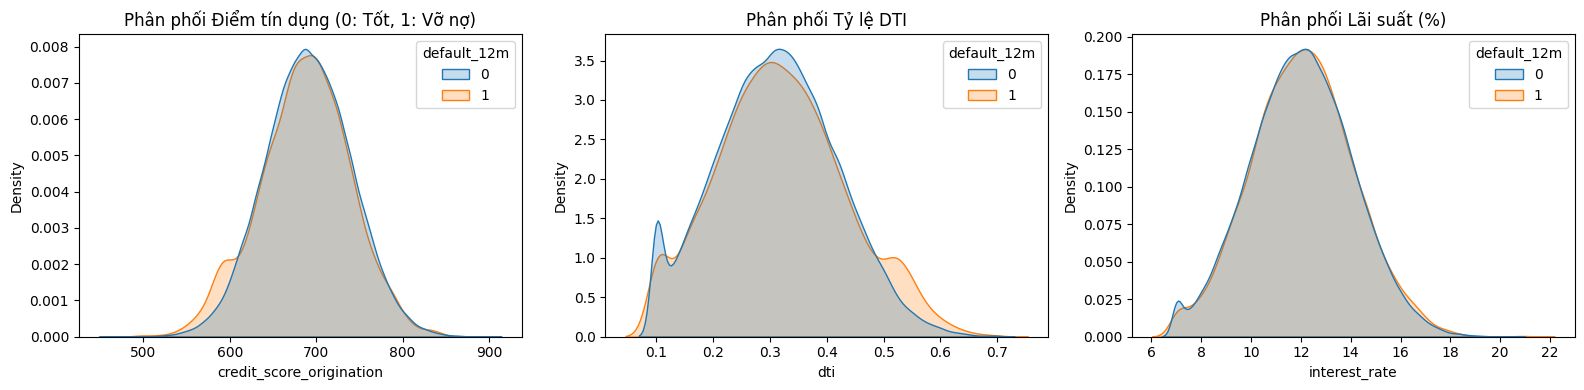

In [38]:
df_eda = con.execute("""
    SELECT credit_score_origination, dti, interest_rate, default_12m
    FROM clean_origination
""").df()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.kdeplot(data=df_eda, x='credit_score_origination', hue='default_12m', fill=True, ax=axes[0], common_norm=False)
axes[0].set_title('Phân phối Điểm tín dụng (0: Tốt, 1: Vỡ nợ)')

sns.kdeplot(data=df_eda, x='dti', hue='default_12m', fill=True, ax=axes[1], common_norm=False)
axes[1].set_title('Phân phối Tỷ lệ DTI')

sns.kdeplot(data=df_eda, x='interest_rate', hue='default_12m', fill=True, ax=axes[2], common_norm=False)
axes[2].set_title('Phân phối Lãi suất (%)')

plt.tight_layout()
plt.show()

*   Rủi ro tập trung mạnh ở phần "đuôi" của Điểm tín dụng và DTI
    - Ở vùng giữa (Điểm tín dụng 620-800 và DTI 20-45%), đường phân phối của nhóm Tốt (xanh) và nhóm Vỡ nợ (cam) chồng lấn gần như hoàn toàn.
    - Tuy nhiên, nhóm Vỡ nợ (màu cam) tách hẳn lên và tạo thành hai "gờ" rủi ro ở hai vùng đuôi: Điểm tín dụng dưới 600 (đuôi trái) và DTI trên 50% (đuôi phải). Đây chính là khu vực cần ưu tiên siết hạn mức.
*   Chưa áp dụng hiệu quả định giá theo rủi ro
    - Phân phối Lãi suất (interest_rate) của nhóm Vỡ nợ và nhóm Tốt gần như trùng khớp 100% --> Công ty đang cho khách hàng rủi ro cao vay với cùng mức lãi suất như khách hàng an toàn, dẫn đến biên lợi nhuận không bù đắp được chi phí dự phòng nợ xấu.
* Vì phần lớn khách hàng vỡ nợ vẫn có hồ sơ ban đầu nằm ở vùng "trung bình/khá" (chồng lấn mạnh với khách hàng tốt), nên chỉ dựa vào khâu thẩm định ban đầu là không đủ --> theo dõi Vintage, Roll Rate và Tín hiệu cảnh báo sớm (EWS) sau khi giải ngân.


## **Ma trận rủi ro**

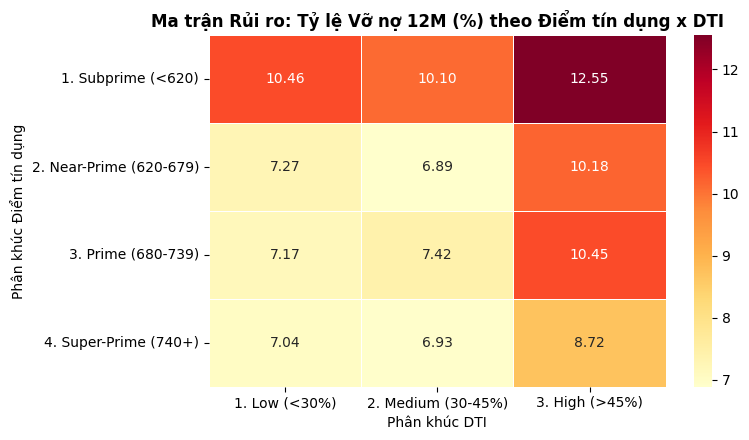

In [39]:
df_matrix = con.execute("""
    SELECT
        CASE
            WHEN credit_score_origination < 620 THEN '1. Subprime (<620)'
            WHEN credit_score_origination < 680 THEN '2. Near-Prime (620-679)'
            WHEN credit_score_origination < 740 THEN '3. Prime (680-739)'
            ELSE '4. Super-Prime (740+)'
        END AS score_band,
        CASE
            WHEN dti < 0.30 THEN '1. Low (<30%)'
            WHEN dti <= 0.45 THEN '2. Medium (30-45%)'
            ELSE '3. High (>45%)'
        END AS dti_band,
        ROUND(AVG(default_12m)*100, 2) AS default_12m_pct
    FROM clean_origination
    GROUP BY 1, 2
""").df()

pivot_npl = df_matrix.pivot(index='score_band', columns='dti_band', values='default_12m_pct')

plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot_npl, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=0.5)
plt.title("Ma trận Rủi ro: Tỷ lệ Vỡ nợ 12M (%) theo Điểm tín dụng x DTI", fontweight='bold')
plt.ylabel("Phân khúc Điểm tín dụng")
plt.xlabel("Phân khúc DTI")
plt.tight_layout()
plt.show()

*   Red zone: Phân khúc Subprime (<620) kết hợp High DTI (>45%) có tỷ lệ vỡ nợ 12M lên tới 12,55% — cao gấp 1,8 lần so với vùng an toàn (6,89% - 7,42%)
*   L-shape
    - Chỉ cần rơi vào Subprime (<620), tỷ lệ vỡ nợ lập tức vượt ngưỡng 10% (10,10% - 12,55%) bất kể DTI thấp hay cao.
    - Chỉ cần DTI vượt 45%, ngay cả nhóm khách hàng điểm tín dụng tốt (Prime 680-739) cũng có tỷ lệ vỡ nợ vọt lên 10,45%.
* Vùng lõi an toàn: Toàn bộ 6 ô thuộc nhóm Điểm tín dụng ≥ 620 và DTI ≤ 45% đều duy trì tỷ lệ vỡ nợ rất ổn định quanh mức 6,89% - 7,42%.




# **RISK ANALYSIS & POLICY SIMULATION**

## **Kiểm tra 2 biến hành vi lúc giải ngân**

In [42]:
print("1. TỶ LỆ VỠ NỢ 12M THEO TỶ LỆ DÙNG HẠN MỨC THẺ")
display(con.execute("""
    SELECT
        CASE
            WHEN revolving_utilization_origination < 0.30 THEN '1. Low (<30%)'
            WHEN revolving_utilization_origination <= 0.60 THEN '2. Medium (30-60%)'
            ELSE '3. High (>60%)'
        END AS util_band,
        COUNT(*) AS loans,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 1) AS share_pct,
        ROUND(AVG(default_12m)*100, 2) AS default_12m_pct
    FROM clean_origination GROUP BY 1 ORDER BY 1
""").df())

print("2. TỶ LỆ VỠ NỢ 12M THEO SỐ LẦN TRA CỨU TÍN DỤNG 12M")
display(con.execute("""
    SELECT
        CASE WHEN credit_inquiries_12m >= 4 THEN '4+' ELSE CAST(credit_inquiries_12m AS VARCHAR) END AS inq_band,
        COUNT(*) AS loans,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 1) AS share_pct,
        ROUND(AVG(default_12m)*100, 2) AS default_12m_pct
    FROM clean_origination GROUP BY 1 ORDER BY 1
""").df())

1. TỶ LỆ VỠ NỢ 12M THEO TỶ LỆ DÙNG HẠN MỨC THẺ


,util_band,loans,share_pct,default_12m_pct
0,1. Low (<30%),78455,58.1,7.76
1,2. Medium (30-60%),51005,37.8,7.61
2,3. High (>60%),5540,4.1,7.31


2. TỶ LỆ VỠ NỢ 12M THEO SỐ LẦN TRA CỨU TÍN DỤNG 12M


,inq_band,loans,share_pct,default_12m_pct
0,0,18373,13.6,7.69
1,1,36596,27.1,7.81
2,2,36653,27.2,7.54
3,3,23946,17.7,7.70
4,4+,19432,14.4,7.67


*   Tỷ lệ dùng hạn mức thẻ lúc vay  không phân tách được rủi ro: Tỷ lệ vỡ nợ 12M giữa 3 nhóm gần như đi ngang ở mức 7,31% - 7,76% (thậm chí nhóm dùng thấp <30% còn hơi nhỉnh hơn ở mức 7,76%).
*   Số lần tra cứu tín dụng cũng không có tín hiệu rõ ràng: Từ 0 lần đến 4+ lần tra cứu, tỷ lệ vỡ nợ đều dao động rất hẹp quanh mức 7,54% - 7,81%.



## **Biểu đồ vintage và xác định giai đoạn nhạy cảm**

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

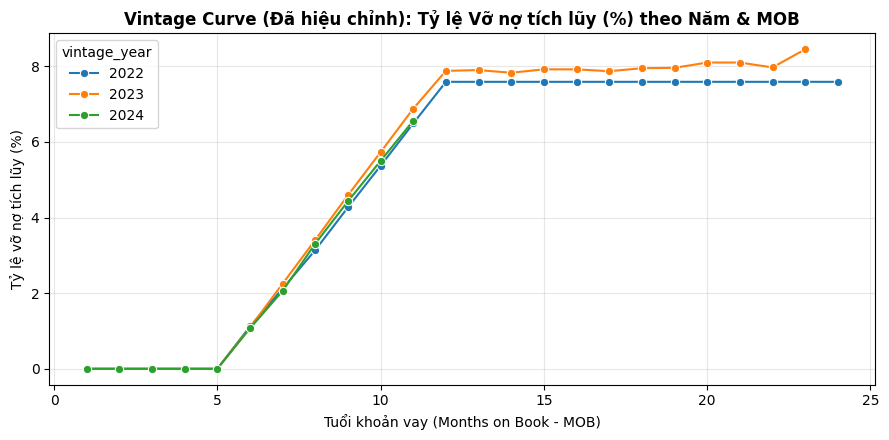

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Đã cập nhật lại 02_vintage_analysis.csv chuẩn xác!


In [45]:
df_v_year = con.execute("""
    SELECT
        o.vintage_year,
        p.months_on_book,
        COUNT(DISTINCT p.customer_id) AS matured_loans,
        ROUND(100.0 * AVG(p.has_defaulted), 2) AS cum_default_pct
    FROM clean_performance p
    JOIN clean_origination o ON p.customer_id = o.customer_id
    WHERE p.months_on_book <= 24
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()

plt.figure(figsize=(9, 4.5))
sns.lineplot(data=df_v_year, x='months_on_book', y='cum_default_pct', hue='vintage_year', marker='o', palette='tab10')
plt.title("Vintage Curve (Đã hiệu chỉnh): Tỷ lệ Vỡ nợ tích lũy (%) theo Năm & MOB", fontweight='bold')
plt.xlabel("Tuổi khoản vay (Months on Book - MOB)")
plt.ylabel("Tỷ lệ vỡ nợ tích lũy (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Xuất lại file 02_vintage_analysis.csv chuẩn bị cho Power BI
df_vintage_fixed = con.execute("""
    SELECT
        o.vintage_year,
        CAST(o.vintage_year AS VARCHAR) || '-Q' || CAST(CEIL(CAST(SUBSTR(o.vintage_month, 6, 2) AS INT) / 3.0) AS INT) AS vintage_quarter,
        p.months_on_book,
        COUNT(DISTINCT p.customer_id) AS matured_loans,
        SUM(p.has_defaulted) AS defaulted_loans,
        ROUND(100.0 * AVG(p.has_defaulted), 2) AS cum_default_rate_pct
    FROM clean_performance p
    JOIN clean_origination o ON p.customer_id = o.customer_id
    WHERE p.months_on_book <= 24
    GROUP BY 1, 2, 3
    ORDER BY 2, 3
""").df()
df_vintage_fixed.to_csv(f'{OUT_DIR}/02_vintage_analysis.csv', index=False)
print("Đã cập nhật lại 02_vintage_analysis.csv chuẩn xác!")

*   Giai đoạn Rủi ro nằm gọn từ MOB 6 - MOB 12: Cả 3 năm giải ngân đều có tỷ lệ vỡ nợ 0% trong 5 tháng đầu (MOB 1-5), sau đó tăng tuyến tính từ MOB 6 đến MOB 12 rồi đi ngang hoàn toàn. Điều này chứng tỏ mọi nỗ lực giám sát và thu hồi nợ sớm cần tập trung tối đa vào khoảng MOB 6 - MOB 12.
*   Năm 2023 có chất lượng kém nhất: Đường 2023 (màu cam) tách hẳn lên trên từ MOB 7 và kết thúc ở mức ~7,9% tại MOB 12 (cao hơn năm 2022 khoảng 0,3 điểm %), đồng thời tăng nhẹ lên ~8,5% ở MOB 23 (do quy mô mẫu nhỏ ở nhóm giải ngân tháng 01/2023).
*   Tín hiệu tích cực ở năm 2024: Đường 2024 (màu xanh lá) bám sát đường 2022 và nằm dưới đường 2023 suốt từ MOB 6 đến MOB 11 (~6,5%), cho thấy chất lượng giải ngân năm 2024 đang dần cải thiện trở lại.



## **Đánh giá hiệu quả cảnh báo sớm**

In [46]:
# Giả sử ngân hàng đặt quy tắc cảnh báo sớm: "Khách hàng có điểm tín dụng giảm >= 15 điểm trong 3 tháng HOẶC mức dùng hạn mức tăng >= 10%" thì sẽ phát hiện sớm được bao nhiêu % khách hàng sắp vỡ nợ?
display(con.execute("""
    WITH first_def AS (
        SELECT customer_id, MIN(months_on_book) AS def_mob
        FROM clean_performance WHERE has_defaulted = 1 GROUP BY 1
    ),
    pre_def_flag AS (
        SELECT
            p.customer_id,
            MAX(CASE WHEN p.credit_score_delta_3m <= -15 THEN 1 ELSE 0 END) AS flag_score_drop,
            MAX(CASE WHEN p.revolving_util_delta_3m >= 0.10 THEN 1 ELSE 0 END) AS flag_util_jump
        FROM clean_performance p
        JOIN first_def fd ON p.customer_id = fd.customer_id
        WHERE (p.months_on_book - fd.def_mob) BETWEEN -3 AND -1
        GROUP BY 1
    )
    SELECT
        COUNT(*) AS total_defaulters_tracked,
        ROUND(100.0 * AVG(flag_score_drop), 2) AS pct_caught_by_score_drop,
        ROUND(100.0 * AVG(flag_util_jump), 2) AS pct_caught_by_util_jump,
        ROUND(100.0 * AVG(GREATEST(flag_score_drop, flag_util_jump)), 2) AS pct_caught_by_either_signal
    FROM pre_def_flag
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_defaulters_tracked,pct_caught_by_score_drop,pct_caught_by_util_jump,pct_caught_by_either_signal
0,7814,49.69,16.1,49.69


*   Phát hiện sớm gần 50% ca vỡ nợ trước 1-3 tháng: Trên tổng số 7.814 khách hàng vỡ nợ được theo dõi, chỉ riêng quy tắc điểm tín dụng giảm >= 15 điểm trong 3 tháng (credit_score_delta_3m <= -15) đã phát hiện sớm được 49,69% trường hợp.  
*   Sụt giảm điểm tín dụng bao trùm hoàn toàn tín hiệu tăng hạn mức thẻ: Tỷ lệ bắt được bằng mức tăng sử dụng hạn mức thẻ là 16,1%, nhưng khi kết hợp cả 2 tín hiệu, tỷ lệ vẫn giữ nguyên ở mức 49,69%. Điều này chứng tỏ 100% khách hàng có dấu hiệu tăng nóng hạn mức thẻ đều đã bị tụt điểm tín dụng trước đó.
*   Nửa còn lại (~50,3%) vỡ nợ đột ngột: Vì một nửa số khách hàng không lộ dấu hiệu tụt điểm mạnh trước khi vỡ nợ, nên chỉ giám sát sau giải ngân là chưa đủ - bắt buộc phải kết hợp siết chặt khẩu vị rủi ro ngay từ khâu thẩm định đầu vào.





## **Mô phỏng chính sách siết hạn mức**

So sánh 2 kịch bản cắt giảm rủi ro trên "Vùng đỏ chữ L" để có con số định lượng:
    - Kịch bản A (Nhẹ): Chỉ từ chối ô đỏ đậm nhất (Score < 620 VÀ DTI > 45%).
    - Kịch bản B (Mạnh): Từ chối toàn bộ Vùng đỏ chữ L (Score < 620 HOẶC DTI > 45%).

In [47]:
display(con.execute("""
    WITH stats AS (
        SELECT
            SUM(loan_amount) AS base_vol,
            SUM(CASE WHEN default_12m = 1 THEN loan_amount ELSE 0 END) AS base_loss,
            -- Kịch bản A: Cắt Subprime + High DTI
            SUM(CASE WHEN NOT (credit_score_origination < 620 AND dti > 0.45) THEN loan_amount ELSE 0 END) AS vol_A,
            SUM(CASE WHEN NOT (credit_score_origination < 620 AND dti > 0.45) AND default_12m = 1 THEN loan_amount ELSE 0 END) AS loss_A,
            -- Kịch bản B: Cắt Subprime HOẶC High DTI
            SUM(CASE WHEN NOT (credit_score_origination < 620 OR dti > 0.45) THEN loan_amount ELSE 0 END) AS vol_B,
            SUM(CASE WHEN NOT (credit_score_origination < 620 OR dti > 0.45) AND default_12m = 1 THEN loan_amount ELSE 0 END) AS loss_B
        FROM clean_origination
    )
    SELECT '0. Hiện tại (Baseline)' AS scenario,
           ROUND(100.0 * base_loss / base_vol, 2) AS npl_rate_pct,
           0.0 AS vol_sacrificed_pct, 0.0 AS loss_avoided_pct FROM stats
    UNION ALL
    SELECT 'A. Siết Subprime + High DTI',
           ROUND(100.0 * loss_A / vol_A, 2),
           ROUND(100.0 * (1 - vol_A / base_vol), 2),
           ROUND(100.0 * (1 - loss_A / base_loss), 2) FROM stats
    UNION ALL
    SELECT 'B. Siết toàn bộ Vùng đỏ chữ L',
           ROUND(100.0 * loss_B / vol_B, 2),
           ROUND(100.0 * (1 - vol_B / base_vol), 2),
           ROUND(100.0 * (1 - loss_B / base_loss), 2) FROM stats
""").df())

,scenario,npl_rate_pct,vol_sacrificed_pct,loss_avoided_pct
0,0. Hiện tại (Baseline),7.68,0.00,0.00
1,A. Siết Subprime + High DTI,7.64,0.75,1.27
2,B. Siết toàn bộ Vùng đỏ chữ L,7.16,16.75,22.34


*   Kịch bản A (Siết Subprime + High DTI) — Hiệu suất cắt lỗ cao nhất nhưng tác động tổng thể nhỏ:
    - Chỉ cần hy sinh 0,75% doanh số giải ngân nhưng tránh được 1,27% tổng thiệt hại nợ xấu (hiệu suất cắt lỗ đạt 1,69 lần), giúp tỷ lệ NPL giảm nhẹ từ 7,68% xuống 7,64% (-4 bps).
*   Kịch bản B (Siết toàn bộ Vùng đỏ chữ L: Score < 620 HOẶC DTI > 45%) — Giảm nợ xấu nhưng phải hy sinh doanh số lớn:
    - Tránh được tới 22,34% tổng thiệt hại nợ xấu, kéo tỷ lệ NPL toàn danh mục giảm mạnh 52 bps (từ 7,68% xuống 7,16%).
    - Tuy nhiên, cái giá phải trả là mất 16,75% doanh số giải ngân (hiệu suất cắt lỗ 1,33 lần).
    

